# W7 — wskazówki AgriScreen potwierdzone pomiarami (D-093)

**Pytanie.** Czy wskazówki z panelu trafiają częściej niż przypadek, gdy sprawdzimy je na **rzeczywistych pomiarach
naziemnych**? Nie oceniamy dokładnej wilgotności gleby ani stanu wody w winorośli, tylko to, czy wskazówka trafia.

**Zasady** (protokół `docs/evidence/W7_protokol_wskazowki.md`, zarejestrowany przed liczeniem):
- prawda = tylko wartości zmierzone (znacznik jakości 0) i oficjalne rejestry; wartości uzupełnione modelem odrzucone;
- stacje wybrane regułą: wszystkie stacje ICOS we Francji z produktem L2 Fluxnet + czujnik ISMN w Condom;
- produkt bez zmian (ERA5-Land, Sentinel-2, progi z panelu);
- dwa testy rozstrzygające: **K1** „gleba sucha” i **K2** „roślinność poniżej swojej normy”;
  kryterium: lepiej niż przypadek (dolna granica przedziału > 0) **i** potwierdzenie w ≥ 6 na 10 przypadków;
- testy na danych do 30.09.2026; wynik negatywny pokazujemy tak samo jak pozytywny.

## 0. Protokół, dane i ich pochodzenie

In [1]:
import os, sys, json, warnings
warnings.filterwarnings('ignore')
CODE_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', '..')) if os.path.basename(os.getcwd()) == 'experiments' \
    else os.path.abspath('.')
sys.path.insert(0, CODE_DIR)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from agriscreen import local, parcel, weather
from agriscreen.config import make_config, era5_csv
from agriscreen.experiments import w7, w7_data

settings = local.load_settings()
cfg = make_config(CODE_DIR, data_dir=settings['data_dir'])
REF = cfg['REF_DIR']; W7DIR = os.path.join(settings['data_dir'], 'data', 'W7_stacje'); OUT = cfg['OUTPUT_DIR']
sha = parcel.protocol_sha(os.path.join(CODE_DIR, 'docs', 'evidence', 'W7_protokol_wskazowki.md'))
assert sha['status'] == 'REGISTERED' and sha['sha256'] == sha['registered'], f'protokół zmieniony: {sha}'
print(f"Protokół W7: {sha['status']}, SHA-256 {sha['sha256'][:16]}… (zgodny z zarejestrowanym); zamrożenie {w7.FREEZE}")
meta = pd.read_csv(os.path.join(REF, 'W7_stations.csv'))
man = w7_data.read_manifest(os.path.join(REF, 'MANIFEST_W7.csv'))
show = man.assign(sha256=man['sha256'].str[:12] + '…', MB=(man['bytes'].astype(float) / 1e6).round(1))
display(meta)
display(show[['station', 'spec', 'file_name', 'downloaded_utc', 'MB', 'sha256', 'licence']])

Protokół W7: REGISTERED, SHA-256 a6689c13870ca7a0… (zgodny z zarejestrowanym); zamrożenie 2026-09-30


,station,name,ecosystem,lat,lon,vegetation_test
0,FR-Aur,Aurade,Croplands,43.549650,1.106103,False
1,FR-Bil,Bilos,Evergreen Needleleaf Forests,44.493652,-0.956092,True
2,FR-Fon,Fontainebleau-Barbeau,Deciduous Broadleaf Forests,48.476357,2.780096,True
3,FR-Gri,Grignon,Croplands,48.844220,1.951910,False
4,FR-Hes,Hesse,Deciduous Broadleaf Forests,48.674100,7.064650,True
5,FR-Lam,Lamasquere,Croplands,43.496437,1.237878,False
6,FR-Lus,Lusignan,Grasslands,46.414246,0.120652,True
7,FR-Mej,Mejusseaume,Grasslands,48.118400,-1.796350,True
8,FR-Pue,Puechabon,Evergreen Broadleaf Forests,43.741300,3.595700,True
9,FR-Tou,Toulouse,Grasslands,43.572857,1.374740,True


,station,spec,file_name,downloaded_utc,MB,sha256,licence
0,FR-Bil,ETC L2 ARCHIVE,ICOSETC_FR-Bil_ARCHIVE_INTERIM_L2.zip,2026-11-01T23:14:33Z,157.9,af02ef360514…,CC BY 4.0 (ICOS data licence)
1,FR-Aur,ETC L2 ARCHIVE,ICOSETC_FR-Aur_ARCHIVE_L2.zip,2026-11-01T23:16:00Z,98.7,1385e6ff809f…,CC BY 4.0 (ICOS data licence)
2,FR-Fon,ETC L2 ARCHIVE,ICOSETC_FR-Fon_ARCHIVE_INTERIM_L2.zip,2026-11-01T23:18:39Z,171.7,af7a04cc6c02…,CC BY 4.0 (ICOS data licence)
3,douane,Relevé par département de la production des vi...,douane_releve_departement_2016.xls,2026-11-01T23:19:08Z,0.0,9c249732edf9…,douane.gouv.fr open data (réutilisation libre)
4,douane,Relevé par département de la production des vi...,douane_releve_departement_2017.xls,2026-11-01T23:19:08Z,0.0,d654037f462b…,douane.gouv.fr open data (réutilisation libre)
5,douane,Relevé par département de la production des vi...,douane_releve_departement_2018.xls,2026-11-01T23:19:08Z,0.0,0b19619c8681…,douane.gouv.fr open data (réutilisation libre)
6,douane,Relevé par département de la production des vi...,douane_releve_departement_2019.xlsx,2026-11-01T23:19:09Z,0.0,3412dc2d0101…,douane.gouv.fr open data (réutilisation libre)
7,douane,Relevé par département de la production des vi...,douane_releve_departement_2020.xls,2026-11-01T23:19:09Z,0.1,6b4ea985c845…,douane.gouv.fr open data (réutilisation libre)
8,douane,Relevé par département de la production des vi...,douane_releve_departement_2021.xlsx,2026-11-01T23:19:09Z,0.0,951085463622…,douane.gouv.fr open data (réutilisation libre)
9,douane,Relevé par département de la production des vi...,douane_releve_departement_2022.xlsx,2026-11-01T23:19:10Z,0.0,7611adcfa07a…,douane.gouv.fr open data (réutilisation libre)


## 1. K1 — „gleba sucha”: czy czujnik w gruncie był wtedy poniżej swojej normy?
Wskazówka: percentyl ERA5-Land 0–100 cm ≤ 30 (jak karta). Prawda: wilgotność gleby z czujnika (ICOS: warstwa
0–100 cm ważona miąższością; Condom: ISMN 20–30 cm) poniżej mediany tej samej pory roku z **innych lat**.
Dni IV–X do zamrożenia.

In [2]:
FZ = pd.Timestamp(w7.FREEZE)
k1_parts, k1_info = [], []

def k1_rows(site, truth, pct):
    ev = w7.events(truth[truth.index <= FZ])
    d = ev.join(pct.rename('pct'), how='inner').dropna(subset=['pct'])
    d = d[w7._in_months(d.index, w7.SOIL_MONTHS) & (d.index <= FZ)]
    return d.assign(site=site, year=d.index.year, hint_dry=d['pct'] <= w7.DRY_PCT, hint_wet=d['pct'] >= w7.WET_PCT)

for r in meta.itertuples():
    try:
        truth, info = w7.soil_daily(w7.archive_path(REF, r.station), r.station)
        pct = w7.soil_percentile(w7.era5_frame(os.path.join(W7DIR, f'{r.station}_era5_land_daily.csv')), cfg)
        d = k1_rows(r.station, truth, pct)
        k1_parts.append(d)
        k1_info.append({'site': r.station, 'levels_0_1m': info.get('depths'), 'days': len(d),
                        'years': f"{d['year'].min()}–{d['year'].max()}" if len(d) else '—'})
    except Exception as e:
        k1_info.append({'site': r.station, 'levels_0_1m': None, 'days': 0, 'years': f'brak: {type(e).__name__}: {e}'})
# Condom: czujnik ISMN A4 W1 (20–30 cm) i ERA5-Land punktu winnicy
cond = parcel.sensor_daily(cfg)['W1']['sm']
pct_c = w7.soil_percentile(w7.era5_frame(era5_csv(cfg)), cfg)
d = k1_rows('ISMN_Condom', cond, pct_c); k1_parts.append(d)
k1_info.append({'site': 'ISMN_Condom', 'levels_0_1m': '20–30 cm (A4 W1)', 'days': len(d),
                'years': f"{d['year'].min()}–{d['year'].max()}"})
K1 = pd.concat(k1_parts)
display(pd.DataFrame(k1_info))

,site,levels_0_1m,days,years
0,FR-Aur,"{1: 0.05, 2: 0.1, 3: 0.3, 4: 0.5, 5: 1.0}",1079,2019–2025
1,FR-Bil,"{1: 0.052, 2: 0.08, 3: 0.11, 4: 0.2, 5: 0.505,...",1300,2019–2026
2,FR-Fon,"{1: 0.05, 2: 0.15, 3: 0.25, 4: 0.35, 5: 0.45, ...",1345,2019–2026
3,FR-Gri,"{1: 0.05, 2: 0.1, 3: 0.3, 4: 0.6, 5: 0.9}",804,2022–2026
4,FR-Hes,"{1: 0.05, 2: 0.1, 3: 0.2, 4: 0.4, 5: 0.8}",949,2022–2026
5,FR-Lam,"{1: 0.05, 2: 0.1, 3: 0.3, 4: 0.5, 5: 1.0}",713,2020–2024
6,FR-Lus,"{1: 0.05, 2: 0.1, 3: 0.2, 4: 0.3, 5: 0.6, 6: 1.0}",759,2023–2026
7,FR-Mej,"{1: 0.05, 2: 0.15, 3: 0.35, 4: 0.5}",1067,2021–2025
8,FR-Pue,"{1: 0.05, 2: 0.1, 3: 0.2, 4: 0.5, 5: 0.8}",950,2022–2026
9,FR-Tou,"{1: 0.05, 2: 0.1, 3: 0.2, 4: 0.3, 5: 0.4, 6: 0...",1699,2018–2025


In [3]:
def stat_row(name, s, test=None):
    r = {k: s[k] for k in ('p', 'p_lo', 'p_hi', 'b', 'delta', 'delta_lo', 'delta_hi', 'n_hint', 'n_all', 'years_hint', 'sites')}
    r = {'test': name, **r}
    if test: r['werdykt'] = w7.verdict(s)
    return r

s1 = w7.hit_stats(K1, 'hint_dry', 'truth_below')
s1w = w7.hit_stats(K1, 'hint_wet', 'truth_above')
k1_tab = pd.DataFrame([stat_row('K1 gleba sucha → czujnik poniżej normy', s1, True),
                       stat_row('opisowo: gleba wilgotna → czujnik powyżej normy', s1w)])
display(k1_tab.round(3))
per = []
for site, g in K1.groupby('site'):
    h = g[g['hint_dry']]
    per.append({'site': site, 'dni': len(g), 'dni „sucho”': len(h), 'p (trafność)': h['truth_below'].mean() if len(h) else np.nan,
                'b (przypadek)': g['truth_below'].mean()})
k1_sites = pd.DataFrame(per); display(k1_sites.round(3))
print(f"K1: p = {s1['p']:.1%} [{s1['p_lo']:.1%}; {s1['p_hi']:.1%}], przypadek b = {s1['b']:.1%}, "
      f"Δ = {s1['delta']:+.1%} [{s1['delta_lo']:+.1%}; {s1['delta_hi']:+.1%}] → {w7.verdict(s1).upper()}")

,test,p,p_lo,p_hi,b,delta,delta_lo,delta_hi,n_hint,n_all,years_hint,sites,werdykt
0,K1 gleba sucha → czujnik poniżej normy,0.812,0.746,0.878,0.493,0.318,0.119,0.518,4783,12385,11,11,potwierdzone
1,opisowo: gleba wilgotna → czujnik powyżej normy,0.898,0.765,1.000,0.484,0.414,0.273,0.555,3485,12385,10,11,NaN


,site,dni,dni „sucho”,p (trafność),b (przypadek)
0,FR-Aur,1079,365,0.800,0.508
1,FR-Bil,1300,464,0.871,0.520
2,FR-Fon,1345,581,0.849,0.506
3,FR-Gri,804,211,0.758,0.525
4,FR-Hes,949,461,0.837,0.506
5,FR-Lam,713,342,0.904,0.527
6,FR-Lus,759,323,0.858,0.507
7,FR-Mej,1067,409,0.939,0.532
8,FR-Pue,950,320,0.816,0.483
9,FR-Tou,1699,624,0.865,0.508


K1: p = 81.2% [74.6%; 87.8%], przypadek b = 49.3%, Δ = +31.8% [+11.9%; +51.8%] → POTWIERDZONE


## 2. K2 — „roślinność poniżej swojej normy”: czy zmierzone parowanie było wtedy poniżej normy?
Wskazówka: z_woda ≤ −1 dla kwadratu 300 m wokół wieży (produkt bez zmian). Prawda: średnie dzienne parowanie (LE,
tylko półgodziny zmierzone) z okna [t−3, t+3] poniżej mediany z innych lat. Sceny VI–IX do zamrożenia;
7 stacji bez upraw polowych.

In [4]:
k2_parts, k2_info, FLUX = [], [], {}

def k2_rows(site, truth_daily, z, col='z'):
    ev = w7.events(w7.window_mean(truth_daily[truth_daily.index <= FZ]))
    d = z[[col]].rename(columns={col: 'z'}).join(ev, how='inner')
    d = d[w7._in_months(d.index, w7.VEG_MONTHS) & (d.index <= FZ)]
    return d.assign(site=site, year=d.index.year, hint_below=d['z'] <= w7.Z_LOW, hint_above=d['z'] >= w7.Z_HIGH)

for r in meta[meta['vegetation_test']].itertuples():
    try:
        fd = w7.flux_daily(w7.archive_path(REF, r.station), r.station); FLUX[r.station] = fd
        z = w7.station_water_z(os.path.join(W7DIR, r.station), CODE_DIR)
        d = k2_rows(r.station, fd['et_le'], z); k2_parts.append(d)
        k2_info.append({'site': r.station, 'sceny S2 z z_woda': len(z), 'sceny w teście': len(d),
                        'lata': f"{d['year'].min()}–{d['year'].max()}" if len(d) else '—'})
    except Exception as e:
        k2_info.append({'site': r.station, 'sceny S2 z z_woda': 0, 'sceny w teście': 0, 'lata': f'brak: {type(e).__name__}: {e}'})
K2 = pd.concat(k2_parts) if k2_parts else pd.DataFrame()
display(pd.DataFrame(k2_info))

,site,sceny S2 z z_woda,sceny w teście,lata
0,FR-Bil,121,23,2021–2026
1,FR-Fon,109,31,2020–2026
2,FR-Hes,287,85,2022–2026
3,FR-Lus,257,58,2023–2026
4,FR-Mej,195,98,2019–2025
5,FR-Pue,196,18,2022–2025
6,FR-Tou,142,64,2019–2025


In [5]:
s2 = w7.hit_stats(K2, 'hint_below', 'truth_below')
s2a = w7.hit_stats(K2, 'hint_above', 'truth_above')
k2_tab = pd.DataFrame([stat_row('K2 roślinność poniżej normy → parowanie poniżej normy', s2, True),
                       stat_row('opisowo: roślinność powyżej normy → parowanie powyżej normy', s2a)])
display(k2_tab.round(3))
per = []
for site, g in K2.groupby('site'):
    h = g[g['hint_below']]
    per.append({'site': site, 'sceny': len(g), 'sceny „poniżej”': len(h), 'p (trafność)': h['truth_below'].mean() if len(h) else np.nan,
                'b (przypadek)': g['truth_below'].mean(),
                'ρ z_woda–anomalia ET': w7.spearman(g['z'], g['truth'] - g['normal'])})
k2_sites = pd.DataFrame(per); display(k2_sites.round(3))
print(f"K2: p = {s2['p']:.1%} [{s2['p_lo']:.1%}; {s2['p_hi']:.1%}], przypadek b = {s2['b']:.1%}, "
      f"Δ = {s2['delta']:+.1%} [{s2['delta_lo']:+.1%}; {s2['delta_hi']:+.1%}] → {w7.verdict(s2).upper()}")

,test,p,p_lo,p_hi,b,delta,delta_lo,delta_hi,n_hint,n_all,years_hint,sites,werdykt
0,K2 roślinność poniżej normy → parowanie poniże...,0.671,0.330,1.000,0.517,0.153,-0.044,0.351,82,377,8,7,niepotwierdzone
1,opisowo: roślinność powyżej normy → parowanie ...,0.650,0.363,0.937,0.483,0.167,0.005,0.330,60,377,7,7,NaN


,site,sceny,sceny „poniżej”,p (trafność),b (przypadek),ρ z_woda–anomalia ET
0,FR-Bil,23,2,0.500,0.522,0.512
1,FR-Fon,31,6,0.500,0.452,-0.060
2,FR-Hes,85,14,0.143,0.506,-0.435
3,FR-Lus,58,16,0.938,0.569,0.751
4,FR-Mej,98,19,0.789,0.439,0.549
5,FR-Pue,18,3,0.333,0.556,0.005
6,FR-Tou,64,22,0.818,0.625,0.556


K2: p = 67.1% [33.0%; 100.0%], przypadek b = 51.7%, Δ = +15.3% [-4.4%; +35.1%] → NIEPOTWIERDZONE


## 3. Opisowo (bez wpływu na werdykt)
Fotosynteza (GPP, wyliczona z pomiaru CO₂) i udział parowania w energii (EF) zamiast parowania; kwadrat 200 i 500 m;
związek wewnątrz sezonu i między sezonami.

In [6]:
desc = []
for var in ('gpp', 'ef'):
    parts = []
    for r in meta[meta['vegetation_test']].itertuples():
        if r.station not in FLUX: continue
        z = w7.station_water_z(os.path.join(W7DIR, r.station), CODE_DIR)
        parts.append(k2_rows(r.station, FLUX[r.station][var], z))
    if parts:
        desc.append(stat_row(f'R-poniżej → {var.upper()} poniżej normy', w7.hit_stats(pd.concat(parts), 'hint_below', 'truth_below')))
for sid, side in (('VINEYARD_02', 200), ('VINEYARD_03', 500)):
    parts = []
    for r in meta[meta['vegetation_test']].itertuples():
        if r.station not in FLUX: continue
        try:
            z = w7.station_water_z(os.path.join(W7DIR, r.station), CODE_DIR, site_id=sid)
            parts.append(k2_rows(r.station, FLUX[r.station]['et_le'], z))
        except Exception:
            pass
    if parts:
        desc.append(stat_row(f'R-poniżej → ET, kwadrat {side} m', w7.hit_stats(pd.concat(parts), 'hint_below', 'truth_below')))
display(pd.DataFrame(desc).round(3))
a = K2.assign(anom=K2['truth'] - K2['normal'])
within = a.groupby(['site', 'year'])[['z', 'anom']].transform(lambda x: x - x.mean())
seas = a.groupby(['site', 'year'])[['z', 'anom']].mean()
print(f"ρ wewnątrz sezonu = {w7.spearman(within['z'], within['anom']):.2f}; ρ średnich sezonów = {w7.spearman(seas['z'], seas['anom']):.2f} "
      f"(n sezonów = {len(seas)})")

,test,p,p_lo,p_hi,b,delta,delta_lo,delta_hi,n_hint,n_all,years_hint,sites
0,R-poniżej → GPP poniżej normy,1.000,1.000,1.000,0.596,0.404,0.132,0.676,6,47,3,4
1,R-poniżej → EF poniżej normy,0.760,0.106,1.000,0.582,0.178,-0.260,0.617,50,208,8,6
2,"R-poniżej → ET, kwadrat 200 m",0.659,0.335,0.983,0.523,0.136,-0.050,0.321,85,388,8,7
3,"R-poniżej → ET, kwadrat 500 m",0.678,0.340,1.000,0.518,0.160,-0.017,0.336,90,361,8,7


ρ wewnątrz sezonu = 0.12; ρ średnich sezonów = 0.33 (n sezonów = 40)


### Przymrozek i upał (opisowo)
Wskazówka: ERA5-Land w punkcie stacji (progi produktu; w Condom progi z panelu). Prawda: zmierzona Tmin ≤ 0 °C
w sezonie przymrozków, Tmax ≥ 35 °C w sezonie upałów.

In [7]:
rows = []
thr = json.load(open(os.path.join(OUT, 'hazard_thresholds.json'), encoding='utf-8'))
def hazard_rows(site, e, tmin, tmax, f_thr, h_thr):
    out = []
    for kind, season, prod, truth in (('przymrozek', cfg['FROST_SEASON'], e['t2m_min_c'] <= f_thr, tmin <= w7.FROST_T),
                                       ('upał', cfg['HEAT_SEASON'], e['t2m_max_c'] >= h_thr, tmax >= w7.HEAT_T)):
        d = pd.DataFrame({'hint': prod, 'truth': truth.reindex(prod.index)}).dropna()
        d = d[w7._in_season(d.index, season) & (d.index <= FZ)].astype(bool)
        out.append({'site': site, 'zdarzenie': kind, **w7.contingency(d, 'hint', 'truth')})
    return out
for r in meta.itertuples():
    if r.station in FLUX:
        fd = FLUX[r.station]
    else:
        try: fd = w7.flux_daily(w7.archive_path(REF, r.station), r.station)
        except Exception: continue
    e = w7.era5_frame(os.path.join(W7DIR, f'{r.station}_era5_land_daily.csv'))
    rows += hazard_rows(r.station, e, fd['tmin'], fd['tmax'], cfg['FROST_TMIN'], cfg['HEAT_TMAX'])
# Condom: stacje Météo-France z task_weather, ERA5 punktu winnicy, progi z panelu
mfs = pd.read_csv(os.path.join(OUT, 'mf_stations.csv'))
import glob
mf = weather.read_mf(sorted(glob.glob(os.path.join(cfg['MF_DIR'], 'Q_*RR-T-Vent.csv.gz'))), start='2016-01-01')
ec = w7.era5_frame(era5_csv(cfg))
for _, s in mfs.iterrows():
    m = mf['num_poste'].astype(str) == str(s['num_poste'])
    st = mf[m].set_index(pd.to_datetime(mf.loc[m, 'time']).dt.normalize())
    rows += hazard_rows(f"MF {s.get('name', s['num_poste'])}", ec, st['tn'], st['tx'], thr.get('frost', cfg['FROST_TMIN']),
                        thr.get('heat', cfg['HEAT_TMAX']))
hz = pd.DataFrame(rows); display(hz.round(2))

,site,zdarzenie,hits,false_alarms,misses,n_days,POD,FAR
0,FR-Aur,przymrozek,3,0,5,434,0.38,0.00
1,FR-Aur,upał,45,13,17,644,0.73,0.22
2,FR-Bil,przymrozek,0,0,12,496,0.00,NaN
3,FR-Bil,upał,40,16,15,736,0.73,0.29
4,FR-Fon,przymrozek,7,13,0,496,1.00,0.65
5,FR-Fon,upał,17,11,0,736,1.00,0.39
6,FR-Gri,przymrozek,4,8,1,372,0.80,0.67
7,FR-Gri,upał,8,2,14,552,0.36,0.20
8,FR-Hes,przymrozek,10,13,0,310,1.00,0.57
9,FR-Hes,upał,3,4,0,460,1.00,0.57


### Winnice w Gers: plon wina a roślinność 13 winnic (oficjalny rejestr, opisowo)
Plon = produkcja całkowita / powierzchnia winnic w produkcji (deklaracje celne, departament 32). Roślinność =
mediana z_woda 13 winnic z QC w VI–IX. Tylko 9 lat i wiele innych przyczyn (przymrozki 2017 i 2021, grad, mildiu):
bez kryterium.

In [8]:
dg = w7_data.douane_gers(os.path.join(REF, 'douane'))
pa = pd.read_csv(os.path.join(OUT, 'parcel_anomalies.csv'), parse_dates=['time'])
wz = pa[(pa['index'] == 'water') & pa['site_id'].isin(parcel.qc_sites(pa))].dropna(subset=['z'])
wz = wz[wz['time'].dt.month.between(6, 9)]
vy = wz.groupby(wz['time'].dt.year)['z'].median().rename('z_woda_mediana')
g = dg.set_index('year').join(vy, how='left')
display(g.round(2))
gg = g.loc[2017:2025].dropna()
print(f"ρ (plon, mediana z_woda) 2017–2025 = {w7.spearman(gg['yield_hl_ha'], gg['z_woda_mediana']):.2f} (n = {len(gg)})")

,declarations,area_ha,total_hl,yield_hl_ha,z_woda_mediana
year,,,,,
2016,1240,18172.34,1924246.52,105.89,NaN
2017,1154,18476.88,1661986.07,89.95,NaN
2018,998,18952.71,1931309.79,101.90,0.45
2019,981,19585.18,1691710.17,86.38,0.63
2020,953,20093.02,1732079.30,86.20,-0.58
2021,922,20241.07,1329196.42,65.67,1.06
2022,878,20361.89,1227253.31,60.27,-1.81
2023,836,20382.15,1455048.47,71.39,0.37
2024,813,20274.15,1305842.78,64.41,0.88


ρ (plon, mediana z_woda) 2017–2025 = 0.29 (n = 8)


## 4. Werdykt i zapis wyników

,test,p,p_lo,p_hi,b,delta,delta_lo,delta_hi,n_hint,years_hint,sites,werdykt
0,K1 gleba sucha → czujnik poniżej normy,0.812,0.746,0.878,0.493,0.318,0.119,0.518,4783,11,11,potwierdzone
0,K2 roślinność poniżej normy → parowanie poniże...,0.671,0.330,1.000,0.517,0.153,-0.044,0.351,82,8,7,niepotwierdzone


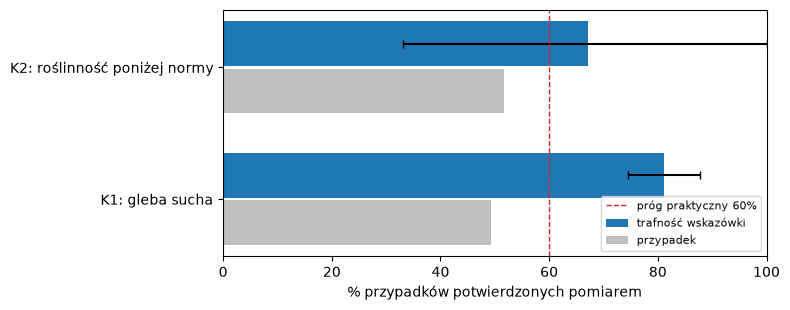

Zapisano: w7_tests.csv, w7_all_rows.csv, w7_k1_sites.csv, w7_k2_sites.csv, w7_hazards.csv, w7_gers_yield.csv, w7_k1_days.csv, w7_k2_scenes.csv


In [9]:
res = pd.concat([k1_tab.iloc[[0]], k2_tab.iloc[[0]]])
display(res[['test', 'p', 'p_lo', 'p_hi', 'b', 'delta', 'delta_lo', 'delta_hi', 'n_hint', 'years_hint', 'sites', 'werdykt']].round(3))
fig, ax = plt.subplots(figsize=(8, 3.2))
lab = ['K1: gleba sucha', 'K2: roślinność poniżej normy']
for i, s in enumerate((s1, s2)):
    ax.barh(i + 0.18, 100 * s['p'], 0.34, color='tab:blue', label='trafność wskazówki' if i == 0 else None)
    ax.errorbar(100 * s['p'], i + 0.18, xerr=[[100 * (s['p'] - s['p_lo'])], [100 * (s['p_hi'] - s['p'])]], color='k', capsize=3)
    ax.barh(i - 0.18, 100 * s['b'], 0.34, color='0.75', label='przypadek' if i == 0 else None)
ax.axvline(60, color='tab:red', ls='--', lw=1, label='próg praktyczny 60%')
ax.set_yticks([0, 1], lab); ax.set_xlim(0, 100); ax.set_xlabel('% przypadków potwierdzonych pomiarem')
ax.legend(fontsize=8, loc='lower right'); plt.tight_layout(); plt.show()
tests = res.assign(protocol_sha256=sha['sha256'], freeze=w7.FREEZE)
tests.to_csv(os.path.join(OUT, 'w7_tests.csv'), index=False)
pd.concat([k1_tab, k2_tab, pd.DataFrame(desc)]).to_csv(os.path.join(OUT, 'w7_all_rows.csv'), index=False)
k1_sites.to_csv(os.path.join(OUT, 'w7_k1_sites.csv'), index=False); k2_sites.to_csv(os.path.join(OUT, 'w7_k2_sites.csv'), index=False)
hz.to_csv(os.path.join(OUT, 'w7_hazards.csv'), index=False); g.to_csv(os.path.join(OUT, 'w7_gers_yield.csv'))
K1.to_csv(os.path.join(OUT, 'w7_k1_days.csv')); K2.to_csv(os.path.join(OUT, 'w7_k2_scenes.csv'))
print('Zapisano: w7_tests.csv, w7_all_rows.csv, w7_k1_sites.csv, w7_k2_sites.csv, w7_hazards.csv, w7_gers_yield.csv, w7_k1_days.csv, w7_k2_scenes.csv')

## 5. Wnioski
Opis wyników i decyzja: `docs/evidence/W7_wyniki.md` (po przebiegu tego notatnika).